In [ ]:
!pip install gdown
import gdown
import pandas as pd
# @title
P1_PATH = gdown.download("https://drive.google.com/uc?id=1J97S0GDy9bJVGO6Hi0c31q-BmpCGEn83", "Phase_1.xlsx", quiet=False)
P2_PATH = gdown.download("https://drive.google.com/uc?id=1JypKPmsKEp_mcumARoE8wF5q7RhKV0EuBTmoTx51Zds", "Phase_2.xlsx", quiet=False)
P3_PATH = gdown.download("https://drive.google.com/uc?id=1pWZIKiGTNkph8zWW35gX-EqzKFy5eSWy", "Phase_3.xlsx", quiet=False)
df1 = pd.read_excel(P1_PATH)
df2 = pd.read_excel(P2_PATH)
df3 = pd.read_excel(P3_PATH)

Downloading...
From: https://drive.google.com/uc?id=1J97S0GDy9bJVGO6Hi0c31q-BmpCGEn83
To: /content/Phase_1.xlsx
100%|██████████| 115k/115k [00:00<00:00, 10.2MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1JypKPmsKEp_mcumARoE8wF5q7RhKV0EuBTmoTx51Zds
From (redirected): https://docs.google.com/spreadsheets/d/1JypKPmsKEp_mcumARoE8wF5q7RhKV0EuBTmoTx51Zds/export?format=xlsx
To: /content/Phase_2.xlsx
212kB [00:00, 3.36MB/s]
Downloading...
From: https://drive.google.com/uc?id=1pWZIKiGTNkph8zWW35gX-EqzKFy5eSWy
To: /content/Phase_3.xlsx
100%|██████████| 367k/367k [00:00<00:00, 25.3MB/s]



Trust effects used in Figure 3
----------------------------------------------------------------------
                outcome                         timing  estimate    ci_low   ci_high        p
 Online political media        Warning shown with clip -0.113431 -0.345640  0.118778 0.338190
 Online political media Warning shown after evaluation -0.511429 -0.743804 -0.279054 0.000017
Political audio content        Warning shown with clip -0.157835 -0.391123  0.075453 0.184824
Political audio content Warning shown after evaluation -0.538571 -0.766600 -0.310543 0.000004


DIRECT TIMING CONTRASTS: PRE-JUDGMENT WARNING VS POST-JUDGMENT DISCLOSURE

1. Correct identification
Pre-warning: 82.5%
Post-judgment initial judgment: 64.7%
Difference = +17.8 pp
OR = 2.567, 95% CI [2.001, 3.292], p = 1.12118e-13

2. Trust in online political media
Pre vs post: b = 0.398, 95% CI [0.166, 0.630], p = 0.00078985

3. Trust in political audio content
Pre vs post: b = 0.381, 95% CI [0.160, 0.602], p = 0.000727

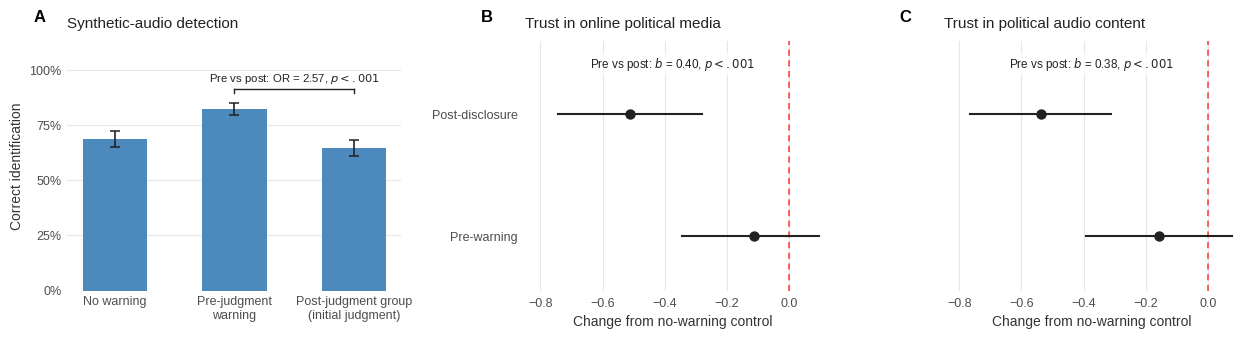

In [ ]:
# @title Figure 3 — Warning timing, discernment, and trust
#
# df3 must already be loaded.
#
# group_no:
#   1 = No warning
#   2 = Pre-judgment warning
#   3 = Post-judgment disclosure
#
# Figure now shows both:
#   1. comparisons with no-warning control
#   2. direct PRE vs POST timing contrasts
# ============================================================


# ============================================================
# IMPORTS
# ============================================================

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import statsmodels.api as sm
import statsmodels.formula.api as smf

from statsmodels.stats.proportion import proportion_confint


# ============================================================
# CHECK DATA
# ============================================================

required_columns = [
    "group_no",
    "realness_perception",
    "trust_media",
    "trust_content"
]

missing = [
    col for col in required_columns
    if col not in df3.columns
]

if missing:
    raise ValueError(
        "Missing columns in df3: "
        + ", ".join(missing)
    )


# ============================================================
# TRUST MODELS
# SAME SPECIFICATIONS AS CURRENT FIGURE 3
# ============================================================

# ------------------------------------------------------------
# Trust in online political media
# ------------------------------------------------------------

media_df = df3[
    [
        "group_no",
        "trust_media"
    ]
].dropna().copy()


media_model = smf.ols(
    "trust_media ~ C(group_no, Treatment(reference=1))",
    data=media_df
).fit()


media_ci = media_model.conf_int()


# ------------------------------------------------------------
# Trust in political audio content
# ------------------------------------------------------------

content_df = df3[
    [
        "group_no",
        "trust_content"
    ]
].dropna().copy()


content_model = smf.ols(
    "trust_content ~ C(group_no, Treatment(reference=1))",
    data=content_df
).fit(
    cov_type="HC3"
)


content_ci = content_model.conf_int()


# ============================================================
# HELPER:
# EFFECT RELATIVE TO NO-WARNING CONTROL
# ============================================================

def extract_effect(
    model,
    ci,
    group
):

    term = (
        "C(group_no, Treatment(reference=1))"
        f"[T.{group}]"
    )

    return {
        "estimate": model.params[term],
        "ci_low": ci.loc[term, 0],
        "ci_high": ci.loc[term, 1],
        "p": model.pvalues[term]
    }


# ============================================================
# CONTROL-RELATIVE TRUST EFFECTS
# ============================================================

trust_rows = []


for group, timing in [
    (2, "Warning shown with clip"),
    (3, "Warning shown after evaluation")
]:

    effect = extract_effect(
        media_model,
        media_ci,
        group
    )

    trust_rows.append({
        "outcome": "Online political media",
        "timing": timing,
        **effect
    })


for group, timing in [
    (2, "Warning shown with clip"),
    (3, "Warning shown after evaluation")
]:

    effect = extract_effect(
        content_model,
        content_ci,
        group
    )

    trust_rows.append({
        "outcome": "Political audio content",
        "timing": timing,
        **effect
    })


trust = pd.DataFrame(
    trust_rows
)


print("\nTrust effects used in Figure 3")
print("-" * 70)
print(
    trust.to_string(
        index=False
    )
)


# ============================================================
# DIRECT TIMING CONTRAST 1
# PRE VS POST:
# CORRECT IDENTIFICATION
# ============================================================

detection_compare = df3.loc[

    df3[
        "group_no"
    ].isin(
        [
            2,
            3
        ]
    ),

    [
        "group_no",
        "realness_perception"
    ]

].dropna().copy()


# Study 3 clips are synthetic.
# realness_perception == 0 means participant judged clip fake,
# therefore correctly identified the synthetic clip.

detection_compare[
    "correct_identification"
] = (

    detection_compare[
        "realness_perception"
    ].eq(
        0
    )

).astype(int)


# ------------------------------------------------------------
# Descriptive rates
# ------------------------------------------------------------

pre_detection = detection_compare.loc[

    detection_compare[
        "group_no"
    ].eq(
        2
    ),

    "correct_identification"

]


post_detection = detection_compare.loc[

    detection_compare[
        "group_no"
    ].eq(
        3
    ),

    "correct_identification"

]


pre_detection_rate = (
    pre_detection.mean()
)

post_detection_rate = (
    post_detection.mean()
)


detection_difference_pp = (

    pre_detection_rate
    -
    post_detection_rate

) * 100


# ------------------------------------------------------------
# Logistic model:
# post-judgment group = reference
#
# Group 2 coefficient therefore tests PRE vs POST directly.
# ------------------------------------------------------------

detection_direct_model = smf.glm(

    (
        "correct_identification ~ "
        "C(group_no, Treatment(reference=3))"
    ),

    data=detection_compare,

    family=sm.families.Binomial()

).fit()


detection_term = (
    "C(group_no, Treatment(reference=3))[T.2]"
)


detection_beta = (
    detection_direct_model.params[
        detection_term
    ]
)


detection_ci_log = (
    detection_direct_model
    .conf_int()
    .loc[
        detection_term
    ]
)


detection_p = (
    detection_direct_model.pvalues[
        detection_term
    ]
)


detection_or = np.exp(
    detection_beta
)


detection_or_low = np.exp(
    detection_ci_log.iloc[0]
)


detection_or_high = np.exp(
    detection_ci_log.iloc[1]
)


# ============================================================
# HELPER:
# DIRECT PRE VS POST CONTRAST FOR TRUST
# ============================================================

def direct_pre_post_contrast(
    model
):

    pre_term = (
        "C(group_no, Treatment(reference=1))[T.2]"
    )

    post_term = (
        "C(group_no, Treatment(reference=1))[T.3]"
    )


    R = np.zeros(
        len(
            model.params
        )
    )


    R[
        list(
            model.params.index
        ).index(
            pre_term
        )
    ] = 1


    R[
        list(
            model.params.index
        ).index(
            post_term
        )
    ] = -1


    test = model.t_test(
        R
    )


    effect = float(
        np.asarray(
            test.effect
        ).squeeze()
    )


    p = float(
        np.asarray(
            test.pvalue
        ).squeeze()
    )


    ci = np.asarray(
        test.conf_int(
            alpha=0.05
        )
    ).squeeze()


    return {
        "estimate": effect,
        "ci_low": float(ci[0]),
        "ci_high": float(ci[1]),
        "p": p
    }


# ============================================================
# DIRECT TIMING CONTRASTS FOR TRUST
# ============================================================

media_direct = direct_pre_post_contrast(
    media_model
)


content_direct = direct_pre_post_contrast(
    content_model
)


# ============================================================
# PRINT DIRECT CONTRASTS
# ============================================================

print("\n")
print("=" * 78)

print(
    "DIRECT TIMING CONTRASTS: "
    "PRE-JUDGMENT WARNING VS POST-JUDGMENT DISCLOSURE"
)

print("=" * 78)


print(
    "\n1. Correct identification"
)

print(
    f"Pre-warning: "
    f"{pre_detection_rate*100:.1f}%"
)

print(
    f"Post-judgment initial judgment: "
    f"{post_detection_rate*100:.1f}%"
)

print(
    f"Difference = "
    f"{detection_difference_pp:+.1f} pp"
)

print(
    f"OR = {detection_or:.3f}, "
    f"95% CI "
    f"[{detection_or_low:.3f}, "
    f"{detection_or_high:.3f}], "
    f"p = {detection_p:.6g}"
)


print(
    "\n2. Trust in online political media"
)

print(
    f"Pre vs post: "
    f"b = {media_direct['estimate']:.3f}, "
    f"95% CI "
    f"[{media_direct['ci_low']:.3f}, "
    f"{media_direct['ci_high']:.3f}], "
    f"p = {media_direct['p']:.6g}"
)


print(
    "\n3. Trust in political audio content"
)

print(
    f"Pre vs post: "
    f"b = {content_direct['estimate']:.3f}, "
    f"95% CI "
    f"[{content_direct['ci_low']:.3f}, "
    f"{content_direct['ci_high']:.3f}], "
    f"p = {content_direct['p']:.6g}"
)


# ============================================================
# FORMAT P FOR FIGURE
# ============================================================

def format_p(p):

    if p < .001:
        return r"$p<.001$"

    return rf"$p={p:.3f}$"


# ============================================================
# PUBLICATION STYLE
# ============================================================

mpl.rcParams.update({

    "font.family": "sans-serif",

    "font.sans-serif": [
        "Arial",
        "Helvetica",
        "Liberation Sans",
        "DejaVu Sans"
    ],

    "pdf.fonttype": 42,

    "ps.fonttype": 42,

    "font.size": 9.5,

    "axes.titlesize": 11,

    "axes.labelsize": 10,

    "xtick.labelsize": 9,

    "ytick.labelsize": 9,

    "text.color": "#333333",

    "axes.labelcolor": "#333333",

    "axes.titlecolor": "#222222",

    "xtick.color": "#4D4D4D",

    "ytick.color": "#4D4D4D",

    "figure.facecolor": "white",

    "axes.facecolor": "white",

    "axes.spines.top": False,

    "axes.spines.right": False,

    "axes.spines.left": False,

    "axes.spines.bottom": False,

    "savefig.dpi": 600

})


BLUE = "#4C89BD"
RED = "#FF3333"
BLACK = "#222222"
GREY = "#666666"
GRID = "#E6E6E6"


# ============================================================
# FIGURE
# ============================================================

fig, axes = plt.subplots(

    1,

    3,

    figsize=(
        12.6,
        4.15
    ),

    gridspec_kw={

        "width_ratios": [
            1.30,
            1.15,
            1.15
        ]

    }

)


axA, axB, axC = axes


fig.subplots_adjust(

    left=0.06,

    right=0.99,

    bottom=0.23,

    top=0.83,

    wspace=0.40

)


# ============================================================
# PANEL A
# SYNTHETIC-AUDIO DETECTION
# ============================================================

det_rows = []


for g in [
    1,
    2,
    3
]:

    xsub = df3.loc[

        df3[
            "group_no"
        ].eq(
            g
        ),

        "realness_perception"

    ].dropna()


    n = len(
        xsub
    )


    correct = (
        xsub == 0
    ).sum()


    prop = (
        correct / n
    )


    ci_low, ci_high = proportion_confint(

        correct,

        n,

        alpha=0.05,

        method="wilson"

    )


    det_rows.append({

        "group": g,

        "n": n,

        "correct": correct,

        "prop": prop,

        "ci_low": ci_low,

        "ci_high": ci_high

    })


det3 = (

    pd.DataFrame(
        det_rows
    )

    .sort_values(
        "group"
    )

)


x = np.arange(
    3
)


rates = (
    det3[
        "prop"
    ]
    .to_numpy()
)


lower = (

    det3[
        "prop"
    ]

    -
    det3[
        "ci_low"
    ]

).to_numpy()


upper = (

    det3[
        "ci_high"
    ]

    -
    det3[
        "prop"
    ]

).to_numpy()


# ------------------------------------------------------------
# Bars
# ------------------------------------------------------------

axA.bar(

    x,

    rates,

    width=0.54,

    color=BLUE,

    edgecolor="none",

    zorder=3

)


# ------------------------------------------------------------
# 95% CIs
# ------------------------------------------------------------

axA.errorbar(

    x,

    rates,

    yerr=np.vstack([
        lower,
        upper
    ]),

    fmt="none",

    ecolor=BLACK,

    elinewidth=1.2,

    capsize=3.5,

    capthick=1.1,

    zorder=4

)


# ============================================================
# PANEL A:
# DIRECT PRE VS POST BRACKET
# ============================================================

# Top of the relevant confidence intervals
pre_top = (
    det3.loc[
        det3["group"].eq(2),
        "ci_high"
    ].iloc[0]
)


post_top = (
    det3.loc[
        det3["group"].eq(3),
        "ci_high"
    ].iloc[0]
)


# Put bracket safely above both confidence intervals
bracket_y = max(
    pre_top,
    post_top
) + 0.045


bracket_height = 0.018


# Vertical ends
axA.plot(

    [
        1,
        1
    ],

    [
        bracket_y,
        bracket_y + bracket_height
    ],

    color=BLACK,

    linewidth=1.0,

    clip_on=False

)


axA.plot(

    [
        2,
        2
    ],

    [
        bracket_y,
        bracket_y + bracket_height
    ],

    color=BLACK,

    linewidth=1.0,

    clip_on=False

)


# Horizontal connector
axA.plot(

    [
        1,
        2
    ],

    [
        bracket_y + bracket_height,
        bracket_y + bracket_height
    ],

    color=BLACK,

    linewidth=1.0,

    clip_on=False

)


# Direct timing result
axA.text(

    1.5,

    bracket_y + bracket_height + 0.018,

    (
        f"Pre vs post: "
        f"OR = {detection_or:.2f}, "
        f"{format_p(detection_p)}"
    ),

    ha="center",

    va="bottom",

    fontsize=8.2,

    color=BLACK

)


# ------------------------------------------------------------
# Axes
# ------------------------------------------------------------

axA.set_ylim(
    0,
    1.13
)


axA.set_yticks([
    0,
    0.25,
    0.50,
    0.75,
    1.00
])


axA.set_yticklabels([
    "0%",
    "25%",
    "50%",
    "75%",
    "100%"
])


axA.set_xticks(
    x
)


axA.set_xticklabels([

    "No warning",

    "Pre-judgment\nwarning",

    "Post-judgment group\n(initial judgment)"

])


axA.set_ylabel(
    "Correct identification"
)


axA.set_title(

    "Synthetic-audio detection",

    loc="left",

    pad=10

)


axA.grid(

    axis="y",

    color=GRID,

    linewidth=0.8

)


axA.set_axisbelow(
    True
)


axA.tick_params(

    axis="both",

    length=0,

    pad=4

)


axA.text(

    -0.10,

    1.08,

    "A",

    transform=axA.transAxes,

    fontsize=12,

    fontweight="bold",

    color="black"

)


# ============================================================
# HELPER FOR TRUST PANELS
# ============================================================

def trust_panel(
    ax,
    outcome,
    title,
    panel_letter,
    direct_result,
    show_labels=False
):

    post = trust[

        (
            trust[
                "outcome"
            ]
            ==
            outcome
        )

        &

        (
            trust[
                "timing"
            ]
            ==
            "Warning shown after evaluation"
        )

    ].iloc[0]


    pre = trust[

        (
            trust[
                "outcome"
            ]
            ==
            outcome
        )

        &

        (
            trust[
                "timing"
            ]
            ==
            "Warning shown with clip"
        )

    ].iloc[0]


    y_post = 1
    y_pre = 0


    # --------------------------------------------------------
    # Post-judgment disclosure
    # --------------------------------------------------------

    ax.plot(

        [
            post["ci_low"],
            post["ci_high"]
        ],

        [
            y_post,
            y_post
        ],

        color=BLACK,

        linewidth=1.5,

        zorder=2

    )


    ax.scatter(

        post["estimate"],

        y_post,

        s=42,

        color=BLACK,

        zorder=3

    )


    # --------------------------------------------------------
    # Pre-judgment warning
    # --------------------------------------------------------

    ax.plot(

        [
            pre["ci_low"],
            pre["ci_high"]
        ],

        [
            y_pre,
            y_pre
        ],

        color=BLACK,

        linewidth=1.5,

        zorder=2

    )


    ax.scatter(

        pre["estimate"],

        y_pre,

        s=42,

        color=BLACK,

        zorder=3

    )


    # --------------------------------------------------------
    # Zero = no-warning control
    # --------------------------------------------------------

    ax.axvline(

        0,

        color=RED,

        linestyle=(
            0,
            (
                4,
                3
            )
        ),

        linewidth=1.1,

        zorder=1

    )


    # ========================================================
    # NEW:
    # DIRECT PRE VS POST RESULT
    # ========================================================

    ax.text(

        0.50,

        0.91,

        (
            f"Pre vs post: "
            f"$b$ = {direct_result['estimate']:.2f}, "
            f"{format_p(direct_result['p'])}"
        ),

        transform=ax.transAxes,

        ha="center",

        va="center",

        fontsize=8.4,

        color=BLACK,

        bbox=dict(
            facecolor="white",
            edgecolor="none",
            pad=1.5,
            alpha=0.92
        ),

        zorder=6

    )


    # --------------------------------------------------------
    # Axes
    # --------------------------------------------------------

    ax.set_xlim(
        -0.85,
        0.10
    )


    ax.set_xticks([
        -0.8,
        -0.6,
        -0.4,
        -0.2,
        0.0
    ])


    ax.set_ylim(
        -0.45,
        1.60
    )


    ax.set_yticks([
        y_post,
        y_pre
    ])


    if show_labels:

        ax.set_yticklabels([

            "Post-disclosure",

            "Pre-warning"

        ])

    else:

        ax.set_yticklabels(
            []
        )


    ax.set_xlabel(
        "Change from no-warning control"
    )


    ax.set_title(

        title,

        loc="left",

        pad=10

    )


    ax.grid(

        axis="x",

        color=GRID,

        linewidth=0.8

    )


    ax.set_axisbelow(
        True
    )


    ax.tick_params(

        axis="both",

        length=0,

        pad=5

    )


    ax.text(

        -0.15,

        1.08,

        panel_letter,

        transform=ax.transAxes,

        fontsize=12,

        fontweight="bold",

        color="black"

    )


# ============================================================
# PANEL B
# TRUST IN ONLINE POLITICAL MEDIA
# ============================================================

trust_panel(

    axB,

    outcome=
        "Online political media",

    title=
        "Trust in online political media",

    panel_letter=
        "B",

    direct_result=
        media_direct,

    show_labels=
        True

)


# ============================================================
# PANEL C
# TRUST IN POLITICAL AUDIO CONTENT
# ============================================================

trust_panel(

    axC,

    outcome=
        "Political audio content",

    title=
        "Trust in political audio content",

    panel_letter=
        "C",

    direct_result=
        content_direct,

    show_labels=
        False

)


# ============================================================
# SAVE
# ============================================================

plt.savefig(

    "Figure_3_warning_timing.pdf",

    bbox_inches="tight",

    pad_inches=0.03

)


plt.savefig(

    "Figure_3_warning_timing.png",

    dpi=600,

    bbox_inches="tight",

    pad_inches=0.03,

    facecolor="white"

)


plt.show()


STUDY 3 DATA
Rows loaded: 2102

Treatment counts:
group_no
1    700
2    702
3    700
Name: count, dtype: int64

Authenticity judgments by treatment:
          count      mean
group_no                 
1           700  0.311429
2           702  0.175214
3           700  0.352857

Interpretation of mean:
  0 = judged fake
  1 = judged real

FIGURE 4 MODERATION SAMPLE

Groups included:
group_no
1    700
3    700
Name: count, dtype: int64

Analysis sample sizes:
Media trust: 1400
Audio-content trust: 1400

TRUST IN ONLINE POLITICAL MEDIA
POST-CORRECTION × INITIALLY JUDGED REAL
b = -1.148
95% CI = [-1.644, -0.653]
p < .001 (exact p = 5.62857e-06)

TRUST IN POLITICAL AUDIO CONTENT
POST-CORRECTION × INITIALLY JUDGED REAL
b = -1.394
95% CI = [-1.880, -0.907]
p < .001 (exact p = 1.97276e-08)


SIMPLE EFFECTS

------------------------------------------------------------------------
Online political media trust
Post-correction vs no warning | INITIALLY JUDGED FAKE
------------------------------

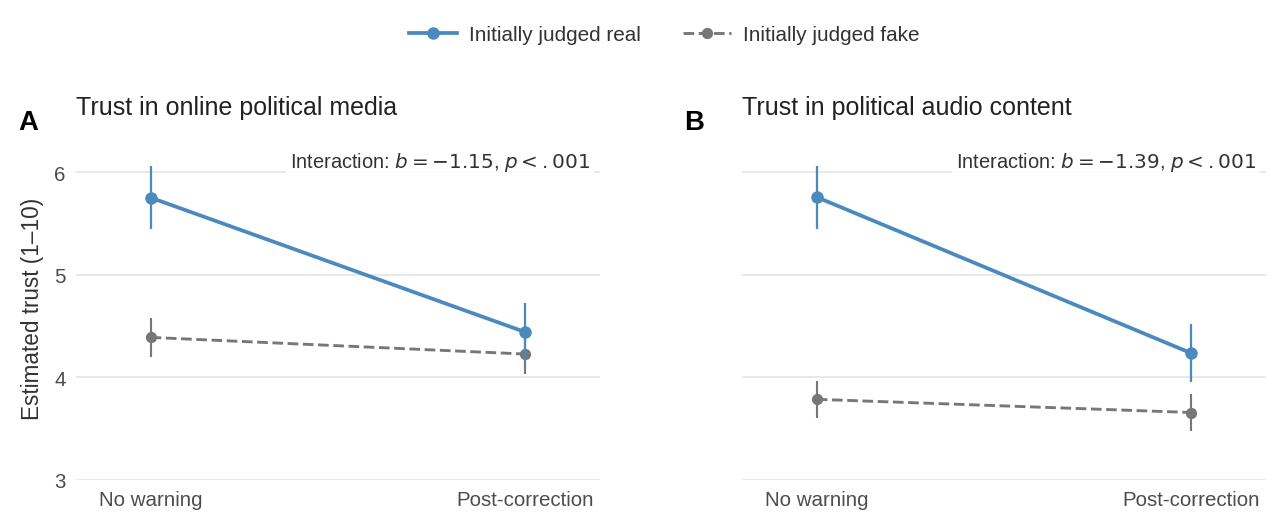


FILES SAVED
Figure_4_initial_judgment_trust.pdf  <-- USE THIS IN LATEX
Figure_4_initial_judgment_trust.png  <-- preview


In [ ]:
# ================================================================
# FIGURE 4
# Initial authenticity judgment moderates the trust consequences
# of post-judgment correction
#
# Study 3
#
# Panel A: Trust in online political media
# Panel B: Trust in political audio content
#
# Statistical question:
#
# Does the effect of POST-JUDGMENT CORRECTION vs NO WARNING
# differ depending on whether participants initially judged
# the synthetic audio as REAL or FAKE?
#
# Model:
#
#   trust ~ treatment * initial authenticity judgment
#
# Analysis sample:
#
#   G1 = No warning
#   G3 = Post-judgment correction
#
# IMPORTANT DESIGN POINT:
#
# In both G1 and G3, authenticity judgment was made without
# a pre-judgment warning.
#
# In G3 specifically, participants judged authenticity BEFORE
# receiving the correction. Therefore realness_perception is
# temporally prior to the post-judgment correction.
#
# Coding:
#
#   group_no:
#       1 = No warning
#       3 = Post-judgment correction
#
#   realness_perception:
#       0 = Initially judged fake
#           = correctly identified synthetic audio
#
#       1 = Initially judged real
#           = misclassified synthetic audio as authentic
#
# Key interaction:
#
#   Post-correction × Initially judged real
#
# A negative interaction means that the post-correction trust
# effect is MORE NEGATIVE among participants who initially
# judged the synthetic clip as real.
#
# Outputs:
#
#   Figure_4_initial_judgment_trust.pdf
#   Figure_4_initial_judgment_trust.png
# ================================================================


# ================================================================
# 0. IMPORTS
# ================================================================

import os

import numpy as np
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D

import statsmodels.formula.api as smf


# ================================================================
# 1. LOAD STUDY 3 DATA
# ================================================================

try:

    import gdown

except ImportError:

    raise ImportError(
        "Install required packages first:\n\n"
        "pip install gdown openpyxl pandas numpy matplotlib statsmodels"
    )


P3_URL = (
    "https://drive.google.com/uc?"
    "id=1pWZIKiGTNkph8zWW35gX-EqzKFy5eSWy"
)

P3_PATH = "Phase_3.xlsx"


if not os.path.exists(P3_PATH):

    print(
        "Downloading Study 3 data..."
    )

    gdown.download(
        P3_URL,
        P3_PATH,
        quiet=False
    )


df3 = pd.read_excel(
    P3_PATH
)


print(
    "\n" + "=" * 72
)

print(
    "STUDY 3 DATA"
)

print(
    "=" * 72
)

print(
    f"Rows loaded: {len(df3)}"
)


# ================================================================
# 2. CHECK REQUIRED VARIABLES
# ================================================================

required = [

    "group_no",

    "realness_perception",

    "trust_media",

    "trust_content"

]


missing = [

    c

    for c in required

    if c not in df3.columns

]


if missing:

    raise ValueError(

        "Missing required Study 3 columns:\n"

        + "\n".join(
            missing
        )

    )


d = df3[
    required
].copy()


# ------------------------------------------------
# Convert safely to numeric
# ------------------------------------------------

for col in required:

    d[col] = pd.to_numeric(

        d[col],

        errors="coerce"

    )


# ------------------------------------------------
# Check treatment coding
# ------------------------------------------------

valid_groups = set(

    d[
        "group_no"
    ]

    .dropna()

    .unique()

)


expected_groups = {
    1,
    2,
    3
}


if not expected_groups.issubset(
    valid_groups
):

    raise ValueError(

        "Expected group_no to contain groups 1, 2, and 3.\n"

        f"Found: {sorted(valid_groups)}"

    )


# ------------------------------------------------
# Check authenticity coding
# ------------------------------------------------

valid_realness = set(

    d[
        "realness_perception"
    ]

    .dropna()

    .unique()

)


if not valid_realness.issubset(
    {
        0,
        1
    }
):

    raise ValueError(

        "realness_perception should contain only:\n"

        "0 = judged fake\n"

        "1 = judged real\n\n"

        f"Found: {sorted(valid_realness)}"

    )


print(
    "\nTreatment counts:"
)

print(

    d[
        "group_no"
    ]

    .value_counts()

    .sort_index()

)


print(
    "\nAuthenticity judgments by treatment:"
)


auth_summary = (

    d

    .groupby(
        "group_no"
    )[
        "realness_perception"
    ]

    .agg([
        "count",
        "mean"
    ])

)


print(
    auth_summary
)


print(

    "\nInterpretation of mean:"

    "\n  0 = judged fake"

    "\n  1 = judged real"

)


# ================================================================
# 3. RESTRICT MODERATION ANALYSIS TO G1 AND G3
#
# G1 = No warning
# G3 = Post-judgment correction
#
# Group 2 is intentionally excluded from this moderation analysis
# because authenticity judgment in Group 2 followed a pre-warning.
#
# The question here is specifically whether the G3-vs-G1 effect
# differs according to the authenticity judgment formed BEFORE
# any corrective information.
# ================================================================

moderation_data = (

    d[
        d[
            "group_no"
        ].isin([
            1,
            3
        ])
    ]

    .copy()

)


# ------------------------------------------------
# Separate outcome-specific complete-case datasets
# ------------------------------------------------

media_data = (

    moderation_data[
        [
            "group_no",

            "realness_perception",

            "trust_media"
        ]
    ]

    .dropna()

    .copy()

)


audio_data = (

    moderation_data[
        [
            "group_no",

            "realness_perception",

            "trust_content"
        ]
    ]

    .dropna()

    .copy()

)


print(
    "\n" + "=" * 72
)

print(
    "FIGURE 4 MODERATION SAMPLE"
)

print(
    "=" * 72
)


print(
    "\nGroups included:"
)

print(

    moderation_data[
        "group_no"
    ]

    .value_counts()

    .sort_index()

)


print(
    "\nAnalysis sample sizes:"
)


print(

    "Media trust:",

    len(
        media_data
    )

)


print(

    "Audio-content trust:",

    len(
        audio_data
    )

)


# ================================================================
# 4. INTERACTION MODELS
#
# Reference treatment:
#
#     G1 = No warning
#
# Reference initial authenticity judgment:
#
#     0 = initially judged fake
#
# HC3 robust covariance is used for BOTH outcomes.
# ================================================================

formula_media = (

    "trust_media ~ "

    "C(group_no, Treatment(reference=1)) * "

    "C(realness_perception, Treatment(reference=0))"

)


formula_audio = (

    "trust_content ~ "

    "C(group_no, Treatment(reference=1)) * "

    "C(realness_perception, Treatment(reference=0))"

)


model_media = smf.ols(

    formula_media,

    data=media_data

).fit(

    cov_type="HC3"

)


model_audio = smf.ols(

    formula_audio,

    data=audio_data

).fit(

    cov_type="HC3"

)


# ================================================================
# 5. HELPERS TO IDENTIFY MODEL TERMS SAFELY
# ================================================================

def find_group_term(
    model,
    group,
    interaction=False
):

    names = list(
        model.params.index
    )


    if interaction:

        candidates = [

            name

            for name in names

            if (

                "group_no" in name

                and f"[T.{group}]" in name

                and "realness_perception" in name

                and ":" in name

            )

        ]


    else:

        candidates = [

            name

            for name in names

            if (

                "group_no" in name

                and f"[T.{group}]" in name

                and ":" not in name

            )

        ]


    if len(candidates) != 1:

        raise RuntimeError(

            "Could not uniquely identify model term.\n"

            f"group={group}\n"

            f"interaction={interaction}\n"

            f"Candidates={candidates}\n"

            f"All parameters={names}"

        )


    return candidates[0]


def find_realness_main_term(
    model
):

    names = list(
        model.params.index
    )


    candidates = [

        name

        for name in names

        if (

            "realness_perception" in name

            and ":" not in name

        )

    ]


    if len(candidates) != 1:

        raise RuntimeError(

            "Could not uniquely identify "
            "realness_perception main effect.\n"

            f"Candidates={candidates}\n"

            f"All parameters={names}"

        )


    return candidates[0]


# ================================================================
# 6. EXTRACT FORMAL INTERACTION
#
# The interaction coefficient answers:
#
# Does the post-correction effect differ between participants
# who initially judged the clip REAL and participants who
# initially judged it FAKE?
#
# If b < 0:
#
# post-correction produces a more negative trust effect among
# participants who initially judged the clip REAL.
# ================================================================

def extract_interaction(
    model,
    label
):

    term = find_group_term(

        model,

        group=3,

        interaction=True

    )


    estimate = float(
        model.params[
            term
        ]
    )


    ci = (
        model
        .conf_int()
        .loc[
            term
        ]
    )


    p = float(
        model.pvalues[
            term
        ]
    )


    result = {

        "estimate":
            estimate,

        "ci_low":
            float(
                ci.iloc[0]
            ),

        "ci_high":
            float(
                ci.iloc[1]
            ),

        "p":
            p

    }


    print(
        "\n" + "=" * 72
    )

    print(
        label.upper()
    )

    print(
        "POST-CORRECTION × INITIALLY JUDGED REAL"
    )

    print(
        "=" * 72
    )


    print(
        f"b = {result['estimate']:.3f}"
    )


    print(

        "95% CI = "

        f"[{result['ci_low']:.3f}, "

        f"{result['ci_high']:.3f}]"

    )


    if result[
        "p"
    ] < .001:

        print(

            "p < .001 "

            f"(exact p = {result['p']:.6g})"

        )

    else:

        print(
            f"p = {result['p']:.4f}"
        )


    return result


media_interaction = extract_interaction(

    model_media,

    "Trust in online political media"

)


audio_interaction = extract_interaction(

    model_audio,

    "Trust in political audio content"

)


# ================================================================
# 7. SIMPLE POST-CORRECTION EFFECTS
#
# Calculates:
#
# G3 post-correction - G1 no warning
#
# separately for:
#
#   initially judged fake
#   initially judged real
#
# For initially judged FAKE:
#
#     effect = beta_G3
#
# For initially judged REAL:
#
#     effect = beta_G3 + beta_G3×real
# ================================================================

def simple_post_effect(
    model,
    initially_real,
    label
):

    names = list(
        model.params.index
    )


    g3_term = find_group_term(

        model,

        group=3,

        interaction=False

    )


    interaction_term = find_group_term(

        model,

        group=3,

        interaction=True

    )


    contrast = np.zeros(
        len(
            names
        )
    )


    # ------------------------------------------------------------
    # Main G3 effect
    # ------------------------------------------------------------

    contrast[
        names.index(
            g3_term
        )
    ] = 1


    # ------------------------------------------------------------
    # Add interaction for initially judged REAL
    # ------------------------------------------------------------

    if initially_real:

        contrast[
            names.index(
                interaction_term
            )
        ] = 1


    test = model.t_test(
        contrast
    )


    estimate = (

        np.asarray(
            test.effect
        )

        .item()

    )


    se = (

        np.asarray(
            test.sd
        )

        .item()

    )


    p = (

        np.asarray(
            test.pvalue
        )

        .item()

    )


    ci = (

        np.asarray(
            test.conf_int(
                alpha=0.05
            )
        )

        .ravel()

    )


    judgment = (

        "INITIALLY JUDGED REAL"

        if initially_real

        else "INITIALLY JUDGED FAKE"

    )


    print(
        "\n" + "-" * 72
    )

    print(
        label
    )

    print(

        "Post-correction vs no warning | "

        + judgment

    )

    print(
        "-" * 72
    )


    print(
        f"b = {estimate:.3f}"
    )


    print(

        "95% CI = "

        f"[{ci[0]:.3f}, "

        f"{ci[1]:.3f}]"

    )


    if p < .001:

        print(

            "p < .001 "

            f"(exact p = {p:.6g})"

        )

    else:

        print(
            f"p = {p:.4f}"
        )


    return {

        "estimate":
            estimate,

        "se":
            se,

        "ci_low":
            ci[0],

        "ci_high":
            ci[1],

        "p":
            p

    }


# ================================================================
# 8. SIMPLE EFFECTS
# ================================================================

print(
    "\n\n" + "=" * 72
)

print(
    "SIMPLE EFFECTS"
)

print(
    "=" * 72
)


# ------------------------------------------------
# Media trust
# ------------------------------------------------

media_fake_effect = simple_post_effect(

    model_media,

    initially_real=False,

    label=
        "Online political media trust"

)


media_real_effect = simple_post_effect(

    model_media,

    initially_real=True,

    label=
        "Online political media trust"

)


# ------------------------------------------------
# Audio-content trust
# ------------------------------------------------

audio_fake_effect = simple_post_effect(

    model_audio,

    initially_real=False,

    label=
        "Political audio-content trust"

)


audio_real_effect = simple_post_effect(

    model_audio,

    initially_real=True,

    label=
        "Political audio-content trust"

)


# ================================================================
# 9. MODEL-ESTIMATED MEANS
#
# We construct the appropriate linear combination of fitted
# coefficients directly.
#
# This avoids the model.model.data.design_info problem and uses
# the model's HC3 covariance matrix for the CIs.
# ================================================================

prediction_grid = pd.DataFrame({

    "group_no": [

        1,

        1,

        3,

        3

    ],

    "realness_perception": [

        0,

        1,

        0,

        1

    ]

})


def robust_predictions(
    model,
    grid
):

    names = list(
        model.params.index
    )


    # ------------------------------------------------------------
    # Intercept
    # ------------------------------------------------------------

    if "Intercept" not in names:

        raise RuntimeError(

            "Intercept not found.\n"

            f"Parameters: {names}"

        )


    intercept_index = names.index(
        "Intercept"
    )


    # ------------------------------------------------------------
    # Main effect of initially judged REAL
    # ------------------------------------------------------------

    realness_term = find_realness_main_term(
        model
    )


    realness_index = names.index(
        realness_term
    )


    results = []


    # ------------------------------------------------------------
    # Construct each cell mean
    # ------------------------------------------------------------

    for _, row in grid.iterrows():


        group = int(
            row[
                "group_no"
            ]
        )


        initially_real = int(
            row[
                "realness_perception"
            ]
        )


        L = np.zeros(
            len(
                names
            ),
            dtype=float
        )


        # Intercept
        L[
            intercept_index
        ] = 1.0


        # --------------------------------------------------------
        # Treatment effect
        # --------------------------------------------------------

        if group != 1:

            treatment_term = find_group_term(

                model,

                group=group,

                interaction=False

            )


            L[
                names.index(
                    treatment_term
                )
            ] = 1.0


        # --------------------------------------------------------
        # Initial judgment main effect
        # --------------------------------------------------------

        if initially_real == 1:

            L[
                realness_index
            ] = 1.0


        # --------------------------------------------------------
        # Interaction
        # --------------------------------------------------------

        if (
            group != 1

            and initially_real == 1
        ):

            interaction_term = find_group_term(

                model,

                group=group,

                interaction=True

            )


            L[
                names.index(
                    interaction_term
                )
            ] = 1.0


        # --------------------------------------------------------
        # HC3 model-based estimate and CI
        # --------------------------------------------------------

        test = model.t_test(
            L
        )


        estimate = (

            np.asarray(
                test.effect
            )

            .item()

        )


        se = (

            np.asarray(
                test.sd
            )

            .item()

        )


        ci = (

            np.asarray(
                test.conf_int(
                    alpha=0.05
                )
            )

            .ravel()

        )


        results.append({

            "group_no":
                group,

            "realness_perception":
                initially_real,

            "estimate":
                estimate,

            "se":
                se,

            "ci_low":
                ci[0],

            "ci_high":
                ci[1]

        })


    return pd.DataFrame(
        results
    )


pred_media = robust_predictions(

    model_media,

    prediction_grid

)


pred_audio = robust_predictions(

    model_audio,

    prediction_grid

)


# ================================================================
# 10. PRINT MODEL-ESTIMATED MEANS
# ================================================================

print(
    "\n\n" + "=" * 72
)

print(
    "MODEL-ESTIMATED MEANS"
)

print(
    "=" * 72
)


print(
    "\nOnline political media trust:"
)


print(

    pred_media

    .round(
        3
    )

    .to_string(
        index=False
    )

)


print(
    "\nPolitical audio-content trust:"
)


print(

    pred_audio

    .round(
        3
    )

    .to_string(
        index=False
    )

)


# ================================================================
# 11. RAW CELL MEANS SANITY CHECK
#
# With this 2 × 2 categorical interaction, fitted means should
# reproduce the observed cell means.
# ================================================================

def print_raw_cell_means(
    data,
    outcome,
    label
):

    raw = (

        data

        .groupby(
            [
                "group_no",

                "realness_perception"
            ]
        )[
            outcome
        ]

        .agg([
            "mean",

            "count"
        ])

    )


    print(
        f"\nRaw cell means: {label}"
    )


    print(
        raw.round(
            3
        )
    )


print_raw_cell_means(

    media_data,

    "trust_media",

    "online political media"

)


print_raw_cell_means(

    audio_data,

    "trust_content",

    "political audio content"

)


# ================================================================
# 12. PUBLICATION STYLE
# ================================================================

mpl.rcParams.update({

    "font.family":
        "sans-serif",

    "font.sans-serif": [

        "Arial",

        "Helvetica",

        "Liberation Sans",

        "DejaVu Sans"

    ],

    "pdf.fonttype":
        42,

    "ps.fonttype":
        42,

    "font.size":
        8.5,

    "axes.titlesize":
        10,

    "axes.titleweight":
        "normal",

    "axes.labelsize":
        9,

    "xtick.labelsize":
        8.2,

    "ytick.labelsize":
        8.2,

    "text.color":
        "#333333",

    "axes.labelcolor":
        "#333333",

    "axes.titlecolor":
        "#222222",

    "xtick.color":
        "#4D4D4D",

    "ytick.color":
        "#4D4D4D",

    "figure.facecolor":
        "white",

    "axes.facecolor":
        "white",

    "axes.spines.top":
        False,

    "axes.spines.right":
        False,

    "axes.spines.left":
        False,

    "axes.spines.bottom":
        False,

    "figure.dpi":
        180,

    "savefig.dpi":
        600

})


# ================================================================
# 13. FIGURE COLOURS
# ================================================================

REAL_COLOR = "#4C89BD"

FAKE_COLOR = "#777777"

GRID_COLOR = "#E8E8E8"

TEXT_COLOR = "#333333"


# ================================================================
# 14. P-VALUE FORMATTER
# ================================================================

def format_p_for_plot(
    p
):

    if p < .001:

        return r"$p<.001$"

    return (
        rf"$p={p:.3f}$"
    )


# ================================================================
# 15. CREATE FIGURE
# ================================================================

fig, (
    axA,
    axB
) = plt.subplots(

    1,

    2,

    figsize=(
        7.35,
        3.35
    ),

    sharey=True

)


fig.subplots_adjust(

    left=0.085,

    right=0.985,

    bottom=0.20,

    top=0.77,

    wspace=0.27

)


# ================================================================
# 16. PANEL FUNCTION
# ================================================================

def draw_interaction_panel(
    ax,
    pred,
    title,
    panel_letter,
    interaction
):

    # ------------------------------------------------------------
    # x:
    #
    # 0 = no warning
    # 1 = post-correction
    # ------------------------------------------------------------

    x = np.array([
        0,
        1
    ])


    # ============================================================
    # INITIALLY JUDGED FAKE
    # ============================================================

    fake = (

        pred[
            pred[
                "realness_perception"
            ] == 0
        ]

        .sort_values(
            "group_no"
        )

    )


    fake_mean = (

        fake[
            "estimate"
        ]

        .to_numpy()

    )


    fake_low = (

        fake[
            "estimate"
        ]

        -
        fake[
            "ci_low"
        ]

    ).to_numpy()


    fake_high = (

        fake[
            "ci_high"
        ]

        -
        fake[
            "estimate"
        ]

    ).to_numpy()


    ax.errorbar(

        x,

        fake_mean,

        yerr=np.vstack([
            fake_low,
            fake_high
        ]),

        fmt="o--",

        color=FAKE_COLOR,

        markersize=4.5,

        linewidth=1.15,

        elinewidth=0.85,

        capsize=2.8,

        capthick=0.85,

        markeredgewidth=0,

        zorder=3

    )


    # ============================================================
    # INITIALLY JUDGED REAL
    # ============================================================

    real = (

        pred[
            pred[
                "realness_perception"
            ] == 1
        ]

        .sort_values(
            "group_no"
        )

    )


    real_mean = (

        real[
            "estimate"
        ]

        .to_numpy()

    )


    real_low = (

        real[
            "estimate"
        ]

        -
        real[
            "ci_low"
        ]

    ).to_numpy()


    real_high = (

        real[
            "ci_high"
        ]

        -
        real[
            "estimate"
        ]

    ).to_numpy()


    ax.errorbar(

        x,

        real_mean,

        yerr=np.vstack([
            real_low,
            real_high
        ]),

        fmt="o-",

        color=REAL_COLOR,

        markersize=5.0,

        linewidth=1.5,

        elinewidth=0.9,

        capsize=2.8,

        capthick=0.9,

        markeredgewidth=0,

        zorder=4

    )


    # ============================================================
    # FORMAL INTERACTION TEST
    #
    # This is the statistical test of whether the two slopes
    # differ.
    # ============================================================

    p_text = format_p_for_plot(
        interaction[
            "p"
        ]
    )


    interaction_text = (

        rf"Interaction: $b={interaction['estimate']:.2f}$, "

        + p_text

    )


    ax.text(

        0.98,

        0.96,

        interaction_text,

        transform=ax.transAxes,

        ha="right",

        va="top",

        fontsize=8.0,

        color=TEXT_COLOR,

        bbox=dict(

            facecolor="white",

            edgecolor="none",

            alpha=0.90,

            pad=1.7

        ),

        zorder=6

    )


    # ============================================================
    # X AXIS
    # ============================================================

    ax.set_xlim(
        -0.20,
        1.20
    )


    ax.set_xticks([
        0,
        1
    ])


    ax.set_xticklabels([

        "No warning",

        "Post-correction"

    ])


    # ============================================================
    # TITLE
    # ============================================================

    ax.set_title(

        title,

        loc="left",

        pad=9

    )


    # ============================================================
    # GRID
    # ============================================================

    ax.set_axisbelow(
        True
    )


    ax.grid(

        axis="y",

        color=GRID_COLOR,

        linewidth=0.75

    )


    ax.grid(

        axis="x",

        visible=False

    )


    # ============================================================
    # TICKS
    # ============================================================

    ax.tick_params(

        axis="both",

        which="both",

        length=0,

        pad=4

    )


    # ============================================================
    # PANEL LETTER
    # ============================================================

    ax.text(

        -0.11,

        1.08,

        panel_letter,

        transform=ax.transAxes,

        fontsize=11,

        fontweight="bold",

        color="#000000",

        ha="left",

        va="top"

    )


# ================================================================
# 17. DRAW PANELS
# ================================================================

draw_interaction_panel(

    axA,

    pred_media,

    "Trust in online political media",

    "A",

    media_interaction

)


draw_interaction_panel(

    axB,

    pred_audio,

    "Trust in political audio content",

    "B",

    audio_interaction

)


# ================================================================
# 18. COMMON Y AXIS
#
# Both outcomes use the same 1–10 response scale.
#
# We retain a focused range because zero is not a valid response
# and the purpose here is to display the interaction.
# ================================================================

axA.set_ylim(
    3.0,
    6.35
)


axA.set_yticks([
    3,
    4,
    5,
    6
])


axA.set_ylabel(
    "Estimated trust (1–10)"
)


# ================================================================
# 19. SHARED LEGEND
# ================================================================

legend_handles = [

    Line2D(

        [0],

        [0],

        color=REAL_COLOR,

        marker="o",

        linestyle="-",

        linewidth=1.5,

        markersize=5,

        markeredgewidth=0,

        label=
            "Initially judged real"

    ),

    Line2D(

        [0],

        [0],

        color=FAKE_COLOR,

        marker="o",

        linestyle="--",

        linewidth=1.15,

        markersize=4.5,

        markeredgewidth=0,

        label=
            "Initially judged fake"

    )

]


fig.legend(

    handles=legend_handles,

    loc="upper center",

    bbox_to_anchor=(
        0.53,
        0.985
    ),

    ncol=2,

    frameon=False,

    fontsize=8.3,

    handlelength=2.3,

    handletextpad=0.6,

    columnspacing=2.0

)


# ================================================================
# 20. EXPORT
# ================================================================

PDF_FILE = (
    "Figure_4_initial_judgment_trust.pdf"
)

PNG_FILE = (
    "Figure_4_initial_judgment_trust.png"
)


plt.savefig(

    PDF_FILE,

    format="pdf",

    bbox_inches="tight",

    pad_inches=0.03

)


plt.savefig(

    PNG_FILE,

    format="png",

    dpi=600,

    bbox_inches="tight",

    pad_inches=0.03,

    facecolor="white"

)


plt.show()


print(
    "\n" + "=" * 72
)

print(
    "FILES SAVED"
)

print(
    "=" * 72
)


print(

    PDF_FILE,

    " <-- USE THIS IN LATEX"

)


print(

    PNG_FILE,

    " <-- preview"

)